# **Feature Story 1 : Analyse exploratoire des données (EDA)**

In [35]:
import mlflow

Importer les données, vérifier types, dimensions et aperçu général.

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

from sklearn.cluster import KMeans, DBSCAN

from sklearn.metrics import davies_bouldin_score,calinski_harabasz_score, silhouette_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

import joblib




path = "https://drive.google.com/uc?id=1_pxeBMqFGuvGzg1lSW_Kqm4VQegsMdUs"

df = pd.read_csv(path,encoding='latin-1')



In [37]:
display(df.shape)
display(df.dtypes)
display(df.head(),df.tail())
df.info()

(8950, 8)

CUST_ID                       str
BALANCE                   float64
PURCHASES                 float64
ONEOFF_PURCHASES          float64
INSTALLMENTS_PURCHASES    float64
CASH_ADVANCE              float64
CREDIT_LIMIT              float64
PAYMENTS                  float64
dtype: object

,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,C10001,40.900749,95.40,0.00,95.4,0.000000,1000.0,201.802084
1,C10002,3202.467416,0.00,0.00,0.0,6442.945483,7000.0,4103.032597
2,C10003,2495.148862,773.17,773.17,0.0,0.000000,7500.0,622.066742
3,C10004,1666.670542,1499.00,1499.00,0.0,205.788017,7500.0,0.000000
4,C10005,817.714335,16.00,16.00,0.0,0.000000,1200.0,678.334763


,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
8945,C19186,28.493517,291.12,0.00,291.12,0.000000,1000.0,325.594462
8946,C19187,19.183215,300.00,0.00,300.00,0.000000,1000.0,275.861322
8947,C19188,23.398673,144.40,0.00,144.40,0.000000,1000.0,81.270775
8948,C19189,13.457564,0.00,0.00,0.00,36.558778,500.0,52.549959
8949,C19190,372.708075,1093.25,1093.25,0.00,127.040008,1200.0,63.165404


<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CUST_ID                 8950 non-null   str    
 1   BALANCE                 8950 non-null   float64
 2   PURCHASES               8950 non-null   float64
 3   ONEOFF_PURCHASES        8950 non-null   float64
 4   INSTALLMENTS_PURCHASES  8950 non-null   float64
 5   CASH_ADVANCE            8950 non-null   float64
 6   CREDIT_LIMIT            8949 non-null   float64
 7   PAYMENTS                8950 non-null   float64
dtypes: float64(7), str(1)
memory usage: 611.9 KB


In [38]:
display(df.isna().sum().sort_values(ascending=False))
display(df[df.isnull().any(axis=1)])

display(df.duplicated("CUST_ID").sum())
display(df.duplicated().sum())

CREDIT_LIMIT              1
CUST_ID                   0
PURCHASES                 0
BALANCE                   0
ONEOFF_PURCHASES          0
INSTALLMENTS_PURCHASES    0
CASH_ADVANCE              0
PAYMENTS                  0
dtype: int64

,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
5203,C15349,18.400472,0.0,0.0,0.0,186.853063,NaN,9.040017


np.int64(0)

np.int64(0)

In [39]:
display(df.describe())

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000
mean,1564.474828,1003.204834,592.437371,411.067645,978.871112,4494.449450,1733.143852
std,2081.531879,2136.634782,1659.887917,904.338115,2097.163877,3638.815725,2895.063757
min,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000
25%,128.281915,39.635000,0.000000,0.000000,0.000000,1600.000000,383.276166
50%,873.385231,361.280000,38.000000,89.000000,0.000000,3000.000000,856.901546
75%,2054.140036,1110.130000,577.405000,468.637500,1113.821139,6500.000000,1901.134317
max,19043.138560,49039.570000,40761.250000,22500.000000,47137.211760,30000.000000,50721.483360


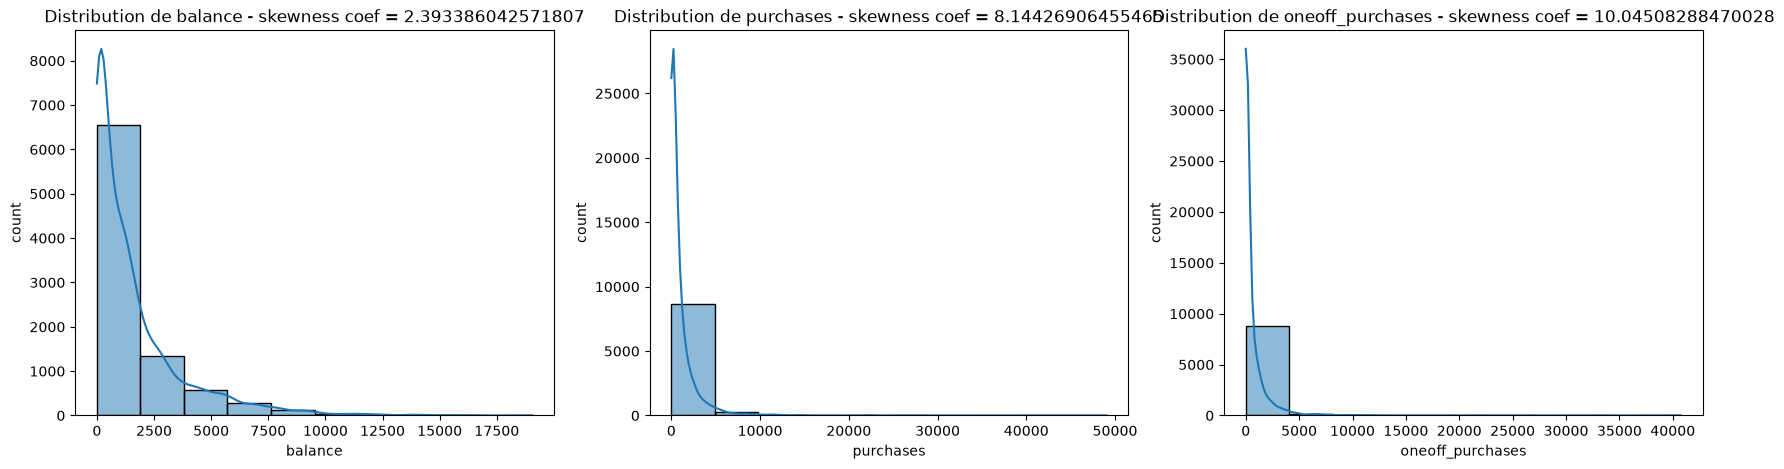

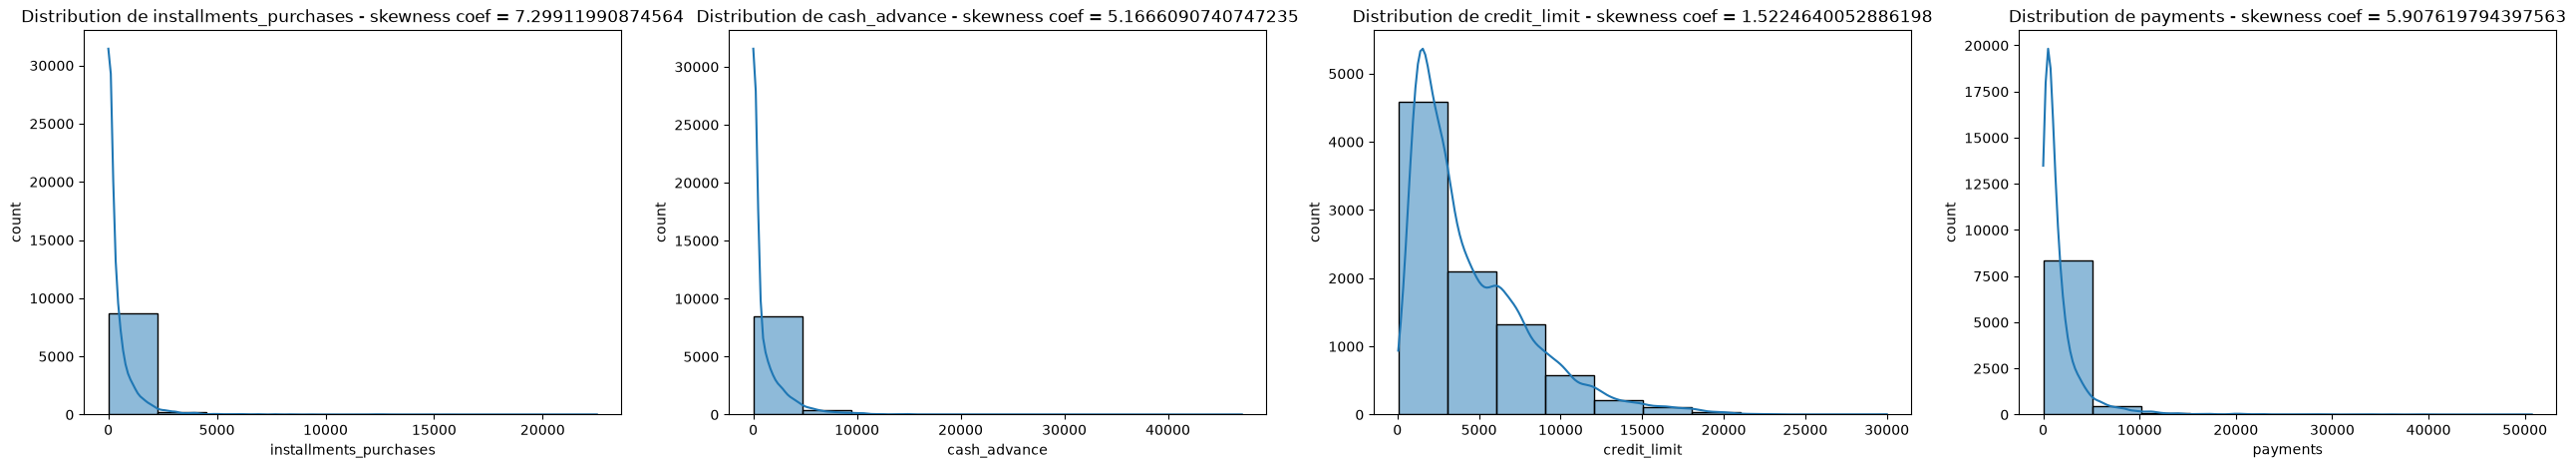

In [40]:
plt.figure(figsize=(21, 5))

for i,col in zip(range(3),["BALANCE", "PURCHASES", 'ONEOFF_PURCHASES']):
  plt.subplot(1, 3, i+1)
  sns.histplot(data=df,x=col,kde=True,bins=10)
  plt.title(f"Distribution de {col.lower()} - skewness coef = {df[col].skew()}")
  plt.xlabel(f"{col.lower()}")
  plt.ylabel("count")

plt.show()

plt.figure(figsize=(32, 5))

for i,col in zip(range(4),[ 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS']):
  plt.subplot(1, 4, i+1)
  sns.histplot(data=df,x=col,kde=True,bins=10)
  plt.title(f"Distribution de {col.lower()} - skewness coef = {df[col].skew()}")
  plt.xlabel(f"{col.lower()}")
  plt.ylabel("count")

plt.show()


<Axes: >

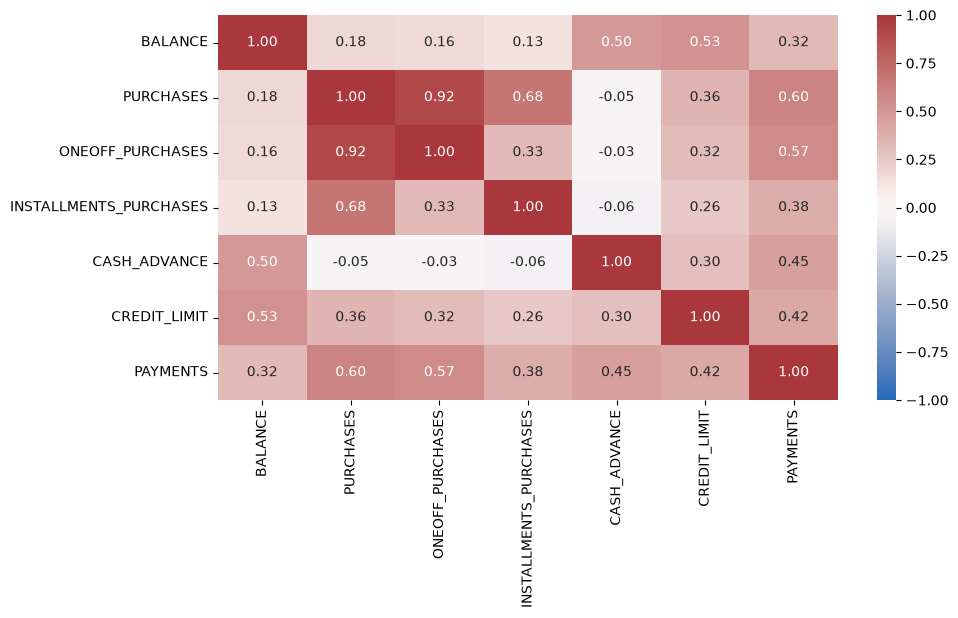

In [41]:
corr_matrix = df.select_dtypes(include="number").corr()
plt.figure(figsize=(10,5))
sns.heatmap(corr_matrix, annot=True, cmap='vlag', vmin=-1,  vmax=1, fmt='.2f')

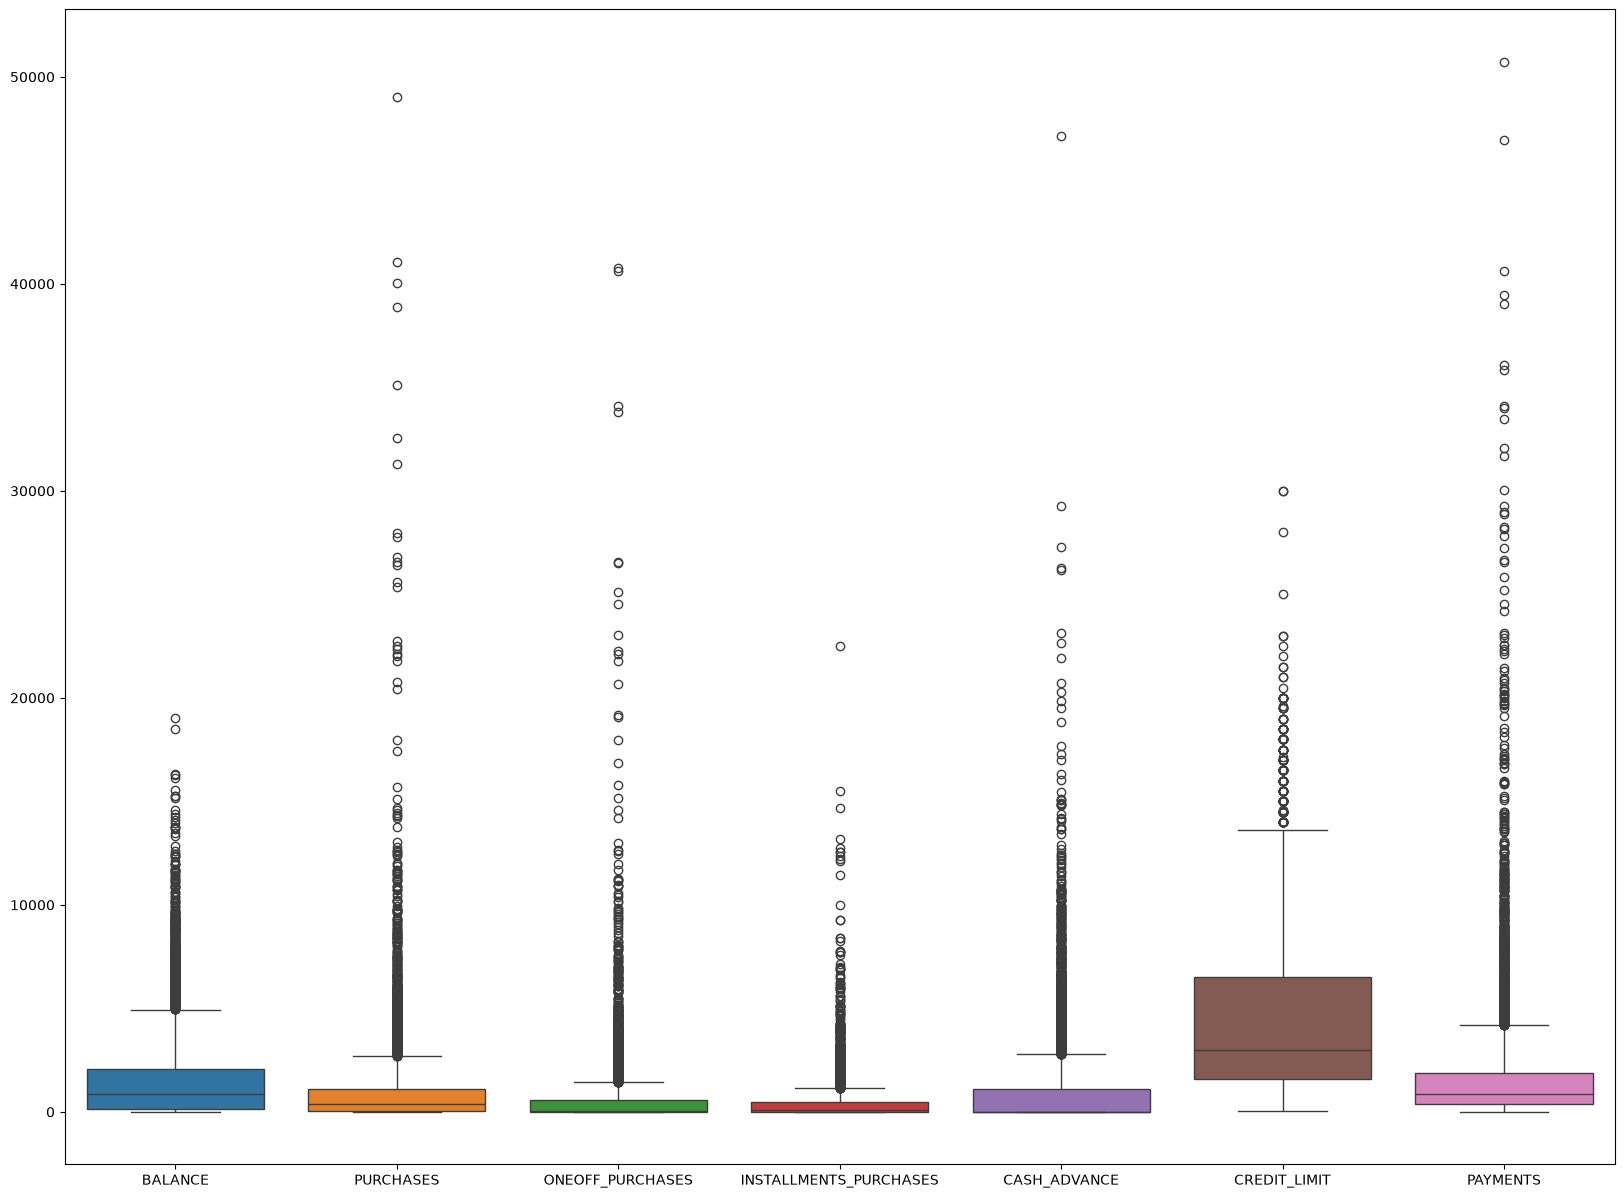

In [42]:
plt.figure(figsize=(20, 15))
sns.boxplot(df)

plt.show()


In [43]:
missing_table = pd.DataFrame({
    'Missing values': df.isnull().sum(),
    'percentage': (df.isnull().sum() / len(df)) * 100
})
missing_table = missing_table.sort_values(by='Missing values', ascending=False)
display(missing_table)

,Missing values,percentage
CREDIT_LIMIT,1,0.011173
CUST_ID,0,0.000000
PURCHASES,0,0.000000
BALANCE,0,0.000000
ONEOFF_PURCHASES,0,0.000000
INSTALLMENTS_PURCHASES,0,0.000000
CASH_ADVANCE,0,0.000000
PAYMENTS,0,0.000000


# Feature Story 2 : Prétraitement des données

In [44]:
clean_df = df.copy()
clean_df = clean_df.drop(columns=["CUST_ID"])

clean_df = clean_df.dropna()

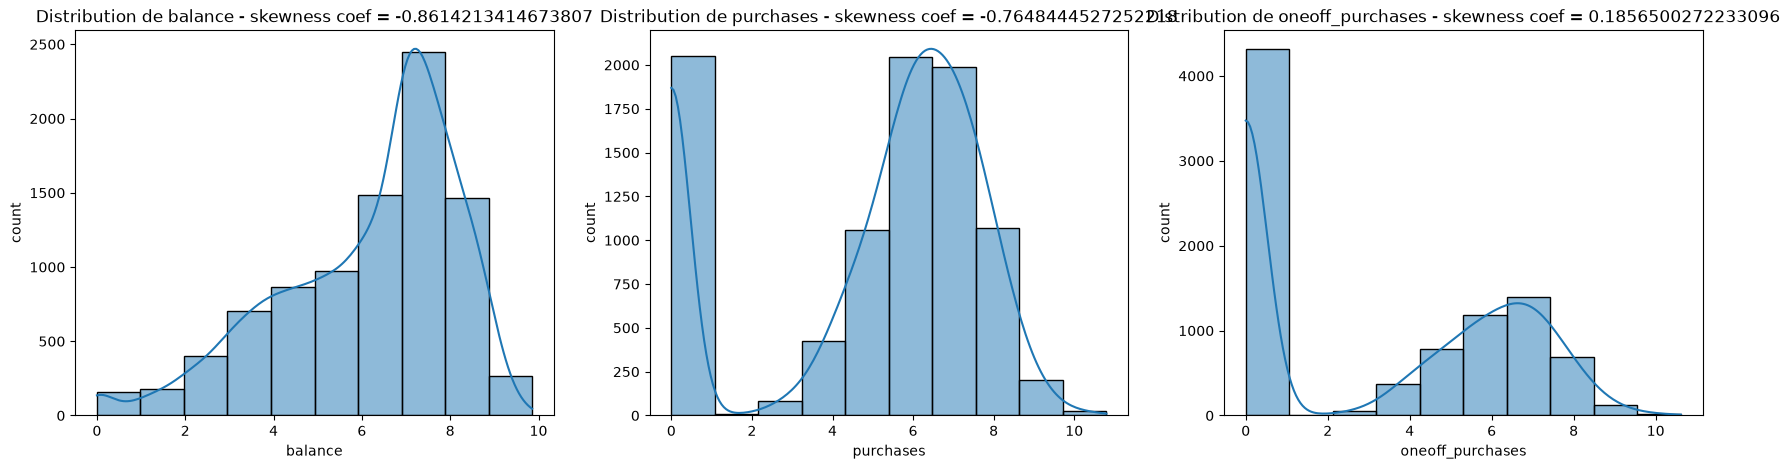

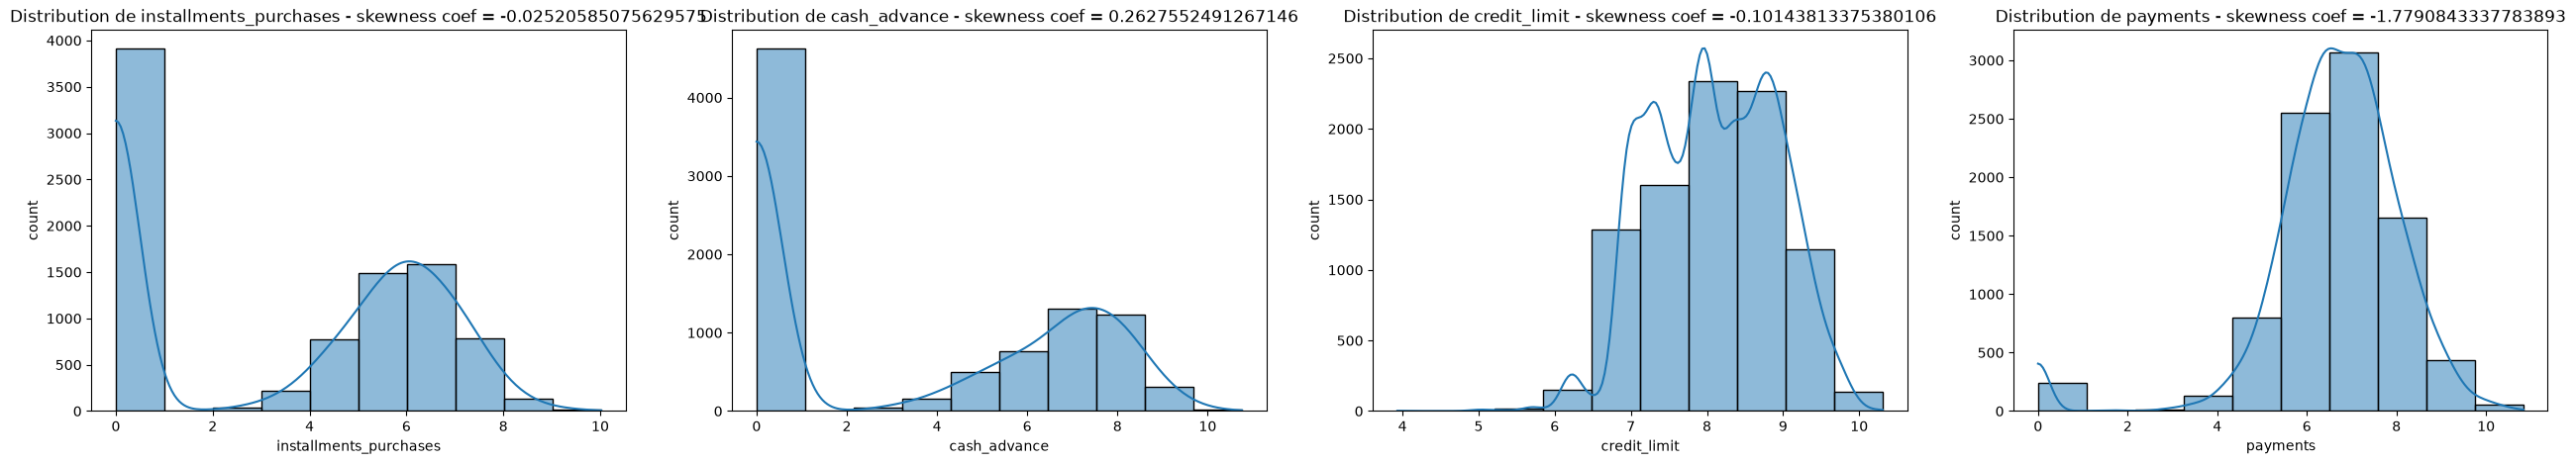

,Original Skew,Clustering Skew
BALANCE,2.393386,-0.861421
PURCHASES,8.144269,-0.764844
ONEOFF_PURCHASES,10.045083,0.185650
INSTALLMENTS_PURCHASES,7.299120,-0.025206
CASH_ADVANCE,5.166609,0.262755
CREDIT_LIMIT,1.522464,-0.101438
PAYMENTS,5.907620,-1.779084


In [45]:
df_clustering = clean_df.copy()
numeric_cols = df_clustering.select_dtypes(include="number").columns

df_clustering[numeric_cols] = np.log1p(df_clustering[numeric_cols])


plt.figure(figsize=(21, 5))

for i,col in zip(range(3),["BALANCE", "PURCHASES", 'ONEOFF_PURCHASES']):
  plt.subplot(1, 3, i+1)
  sns.histplot(data=df_clustering,x=col,kde=True,bins=10)
  plt.title(f"Distribution de {col.lower()} - skewness coef = {df_clustering[col].skew()}")
  plt.xlabel(f"{col.lower()}")
  plt.ylabel("count")

plt.show()

plt.figure(figsize=(32, 5))

for i,col in zip(range(4),[ 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS']):
  plt.subplot(1, 4, i+1)
  sns.histplot(data=df_clustering,x=col,kde=True,bins=10)
  plt.title(f"Distribution de {col.lower()} - skewness coef = {df_clustering[col].skew()}")
  plt.xlabel(f"{col.lower()}")
  plt.ylabel("count")

plt.show()
cols = ["BALANCE", "PURCHASES", 'ONEOFF_PURCHASES','INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS']
skew_comparison = pd.DataFrame({
    "Original Skew": df[cols].skew(),
    "Clustering Skew": df_clustering[cols].skew()
    }
)
display(skew_comparison)

In [46]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clustering[numeric_cols])

In [47]:
pca = PCA(random_state=42)
pca_res = pca.fit(df_scaled)
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)*100
n_components_80 = np.argmax(cumulative_variance>=80) + 1

n_components = len(cumulative_variance)

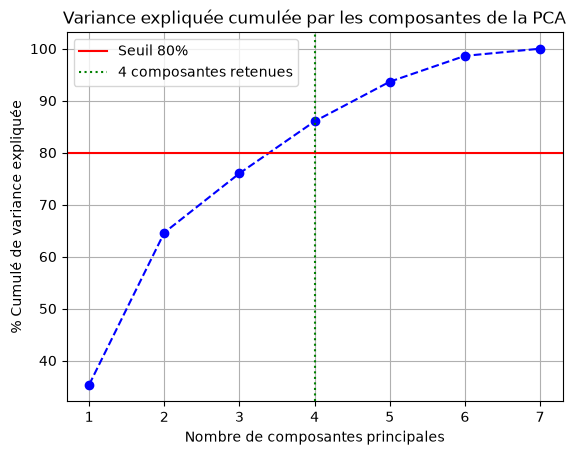

In [48]:
plt.plot(range(1, n_components + 1), cumulative_variance, marker='o', linestyle='--', color='b')
plt.axhline(y=80, color='r', linestyle='-', label='Seuil 80%')

n_retenu = np.argmax(cumulative_variance >= 80) + 1
plt.axvline(x=n_retenu, color='g', linestyle=':', label=f'{n_retenu} composantes retenues')

plt.title("Variance expliquée cumulée par les composantes de la PCA")
plt.xlabel("Nombre de composantes principales")
plt.ylabel("% Cumulé de variance expliquée")
plt.legend()
plt.grid(True)
plt.show()

# Feature Story 3 : Entraînement des modèles de clustering (K-means et DBSCAN)

In [49]:
k_results = []
for component in range(2,6):
  xpca = PCA(n_components=component).fit_transform(df_scaled)
  for k in range(2,8):
    kmean = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmean.fit_predict(xpca)
    inertia = kmean.inertia_
    silouhete = silhouette_score(xpca, labels, random_state=42)
    cluster_counts = np.bincount(labels)
    population_share = cluster_counts / len(labels) * 100

    result = {
        "pca components": component,
        "k": k,
        "inertia": inertia,
        "silouhete": silouhete,
        "cluster counts": cluster_counts,
        "population_share": population_share.round(2)
    }
    k_results.append(result)


,pca components,k,inertia,silouhete,cluster counts,population_share
0,2,2,23542.395938,0.430953,"[6149, 2800]","[68.71, 31.29]"
1,2,3,13244.219895,0.448740,"[2428, 3393, 3128]","[27.13, 37.91, 34.95]"
2,2,4,10414.983259,0.421660,"[2172, 2288, 2758, 1731]","[24.27, 25.57, 30.82, 19.34]"
3,2,5,8242.980510,0.410122,"[2124, 1497, 1447, 2481, 1400]","[23.73, 16.73, 16.17, 27.72, 15.64]"
4,2,6,6689.621477,0.394669,"[1145, 1505, 1444, 1373, 2420, 1062]","[12.79, 16.82, 16.14, 15.34, 27.04, 11.87]"
5,2,7,5634.987347,0.397941,"[985, 1772, 1101, 1373, 1225, 1131, 1362]","[11.01, 19.8, 12.3, 15.34, 13.69, 12.64, 15.22]"
6,3,2,30681.084633,0.368307,"[6157, 2792]","[68.8, 31.2]"
7,3,3,20205.727848,0.382649,"[3571, 2391, 2987]","[39.9, 26.72, 33.38]"
8,3,4,16448.250736,0.388787,"[2412, 1873, 2170, 2494]","[26.95, 20.93, 24.25, 27.87]"
9,3,5,13781.047480,0.390872,"[2162, 1501, 2128, 1745, 1413]","[24.16, 16.77, 23.78, 19.5, 15.79]"


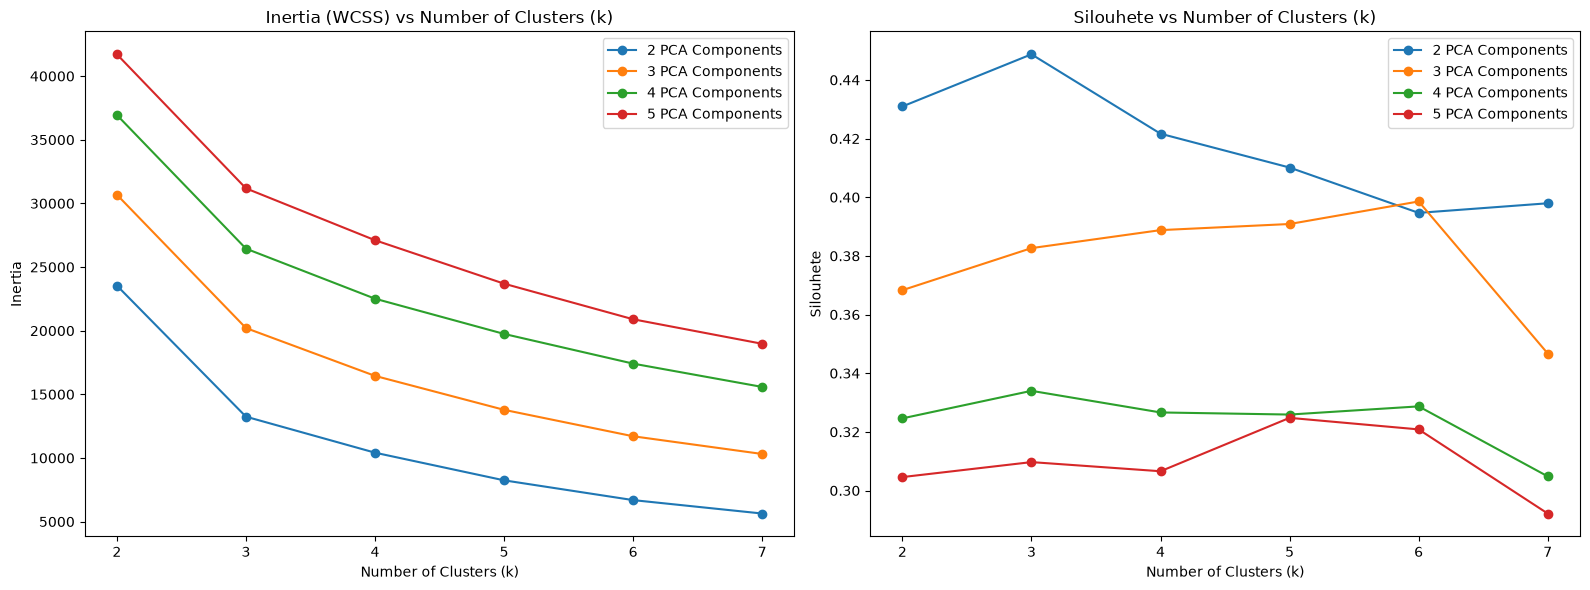

In [50]:
k_df = pd.DataFrame(k_results)

display(k_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for pca, group in k_df.groupby('pca components'):
    ax1.plot(group['k'], group['inertia'], marker='o', label=f'{pca} PCA Components')
    ax2.plot(group['k'], group['silouhete'], marker='o', label=f'{pca} PCA Components')
ax1.set_title('Inertia (WCSS) vs Number of Clusters (k)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.legend()
ax2.set_title('Silouhete vs Number of Clusters (k)')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silouhete')
ax2.legend()

plt.tight_layout()
plt.show()

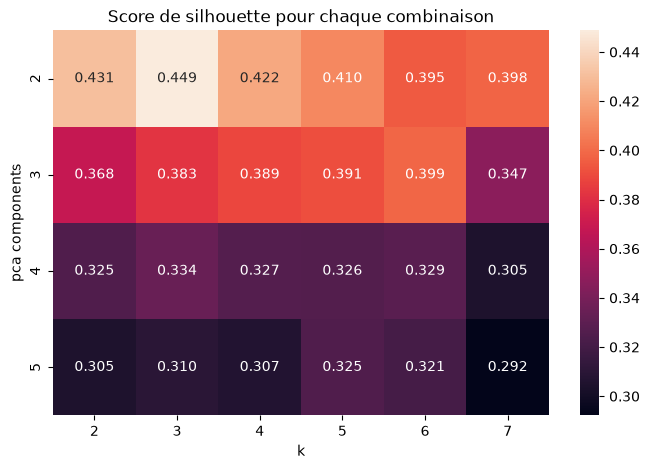

In [51]:
pivot_df = k_df.pivot(index='pca components', columns='k', values='silouhete')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_df, annot=True, fmt=".3f")
plt.title("Score de silhouette pour chaque combinaison")
plt.show()

In [52]:
pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(df_scaled)
final_kmean = KMeans(n_clusters=3, random_state=42, n_init=10)
k_labels = final_kmean.fit_predict(X_pca2)
k_sil_score = silhouette_score(X_pca2,k_labels)
k_db_score = davies_bouldin_score(X_pca2,k_labels)
k_ch_score = calinski_harabasz_score(X_pca2,k_labels)
clean_df["cluster_kmeans"] = k_labels
display(clean_df)

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_kmeans
0,40.900749,95.40,0.00,95.40,0.000000,1000.0,201.802084,2
1,3202.467416,0.00,0.00,0.00,6442.945483,7000.0,4103.032597,0
2,2495.148862,773.17,773.17,0.00,0.000000,7500.0,622.066742,1
3,1666.670542,1499.00,1499.00,0.00,205.788017,7500.0,0.000000,2
4,817.714335,16.00,16.00,0.00,0.000000,1200.0,678.334763,2
...,...,...,...,...,...,...,...,...
8945,28.493517,291.12,0.00,291.12,0.000000,1000.0,325.594462,2
8946,19.183215,300.00,0.00,300.00,0.000000,1000.0,275.861322,2
8947,23.398673,144.40,0.00,144.40,0.000000,1000.0,81.270775,2
8948,13.457564,0.00,0.00,0.00,36.558778,500.0,52.549959,2


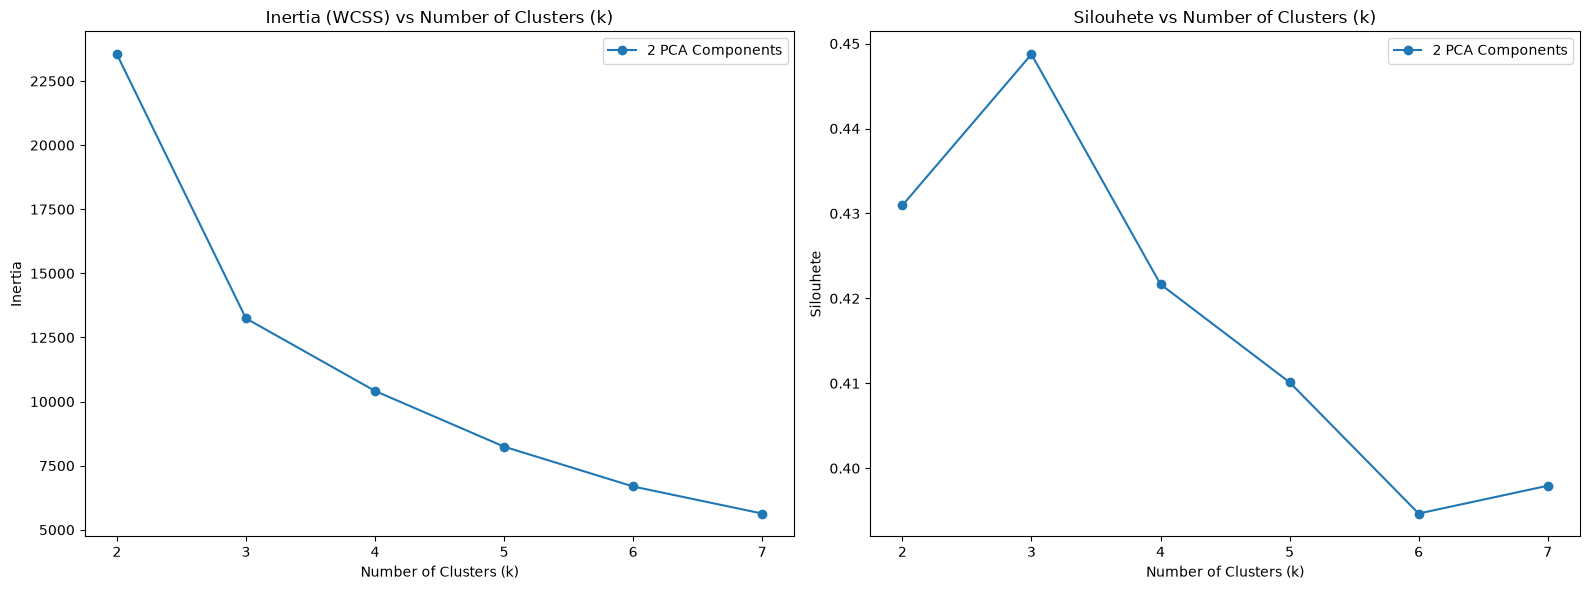

In [53]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for pca, group in k_df[k_df['pca components']==2].groupby('pca components'):
    ax1.plot(group['k'], group['inertia'], marker='o', label=f'{pca} PCA Components')
    ax2.plot(group['k'], group['silouhete'], marker='o', label=f'{pca} PCA Components')
ax1.set_title('Inertia (WCSS) vs Number of Clusters (k)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.legend()
ax2.set_title('Silouhete vs Number of Clusters (k)')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silouhete')
ax2.legend()

plt.tight_layout()
plt.show()

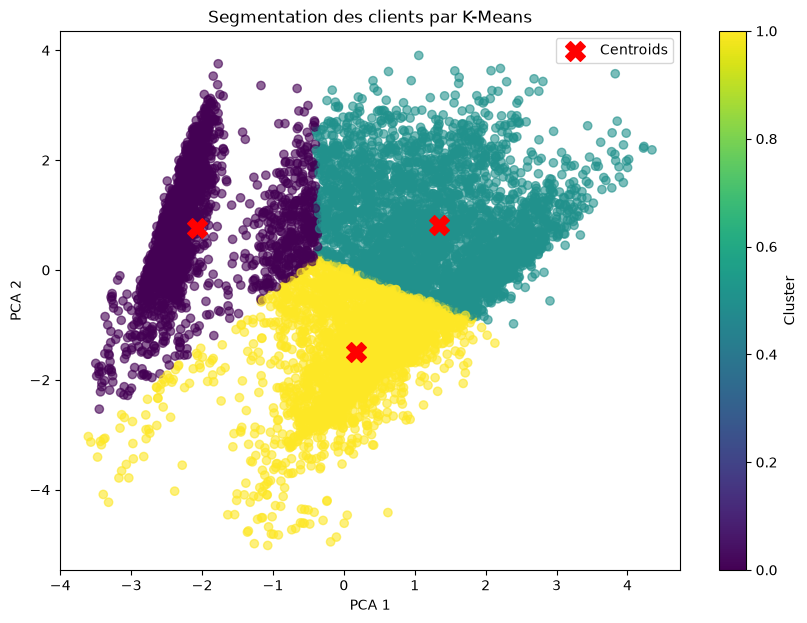

In [54]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca2[:, 0],
    X_pca2[:, 1],
    c=clean_df["cluster_kmeans"],
    alpha=0.6
)

plt.scatter(
    final_kmean.cluster_centers_[:, 0],
    final_kmean.cluster_centers_[:, 1],
    marker="X",
    color="red",
    s=200,
    label="Centroids"
)

plt.title("Segmentation des clients par K-Means")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label="Cluster")
plt.legend()
plt.show()

In [55]:
db_results = []
for component in range(2,7):
  xpca = PCA(n_components=component,random_state=42).fit_transform(df_scaled)
  for eps in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.5]:
    for min_samp in [3, 5, 8, 10, 13, 15, 16, 18]:
      dbscan = DBSCAN(eps=eps, min_samples=min_samp, n_jobs=-1)
      labels = dbscan.fit_predict(xpca)
      unique_clusters = set(labels) - {-1}
      n_clusters = len(unique_clusters)
      n_total = len(labels)
      n_noise = list(labels).count(-1)
      noise_ratio = n_noise / n_total
      est_equilibre = True
      if n_clusters == 0:
          est_equilibre = False
      else:
          for c in unique_clusters:
              percent_cluster = (labels == c).sum() / n_total
              if percent_cluster < 0.10:
                  est_equilibre = False
                  break
      if len(set(labels)) > 1:
        silhouette = silhouette_score(xpca, labels, random_state=42)
      else:
        silhouette = -1.0
      db_results.append({
              'pca components': component,
              'eps': eps,
              'min_samples': min_samp,
              'n_clusters': n_clusters,
              'silhouette': silhouette,
              'noise_propotion': noise_ratio,
              'est_equilibre': est_equilibre
          })


In [56]:
db_df = pd.DataFrame(db_results)
display(db_df[db_df['n_clusters']>2].sort_values(by=["est_equilibre","silhouette"],ascending=False))

,pca components,eps,min_samples,n_clusters,silhouette,noise_propotion,est_equilibre
182,4,0.5,16,3,0.284828,0.104257,True
183,4,0.5,18,3,0.281210,0.114426,True
263,5,0.6,18,4,0.259053,0.131411,True
19,2,0.3,10,3,0.378567,0.010280,False
18,2,0.3,8,3,0.331788,0.008157,False
...,...,...,...,...,...,...,...
224,5,0.2,3,225,-0.525056,0.618505,False
225,5,0.2,5,70,-0.527831,0.715052,False
144,4,0.1,3,190,-0.528924,0.760420,False
296,6,0.2,3,208,-0.546751,0.684769,False


In [57]:
db_pca = PCA(n_components=2,random_state=42).fit_transform(df_scaled)
dbscan = DBSCAN(eps=0.3, min_samples=10)
db_labels = dbscan.fit_predict(db_pca)
db_sil_score = silhouette_score(db_pca,db_labels)
db_db_score = davies_bouldin_score(db_pca,db_labels)
db_ch_score = calinski_harabasz_score(db_pca,db_labels)
clean_df["cluster_dbscan"] = db_labels
clean_df["est_atypique_dbscan"] = db_labels == -1


In [58]:
clean_df

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_kmeans,cluster_dbscan,est_atypique_dbscan
0,40.900749,95.40,0.00,95.40,0.000000,1000.0,201.802084,2,0,False
1,3202.467416,0.00,0.00,0.00,6442.945483,7000.0,4103.032597,0,1,False
2,2495.148862,773.17,773.17,0.00,0.000000,7500.0,622.066742,1,0,False
3,1666.670542,1499.00,1499.00,0.00,205.788017,7500.0,0.000000,2,0,False
4,817.714335,16.00,16.00,0.00,0.000000,1200.0,678.334763,2,0,False
...,...,...,...,...,...,...,...,...,...,...
8945,28.493517,291.12,0.00,291.12,0.000000,1000.0,325.594462,2,0,False
8946,19.183215,300.00,0.00,300.00,0.000000,1000.0,275.861322,2,0,False
8947,23.398673,144.40,0.00,144.40,0.000000,1000.0,81.270775,2,0,False
8948,13.457564,0.00,0.00,0.00,36.558778,500.0,52.549959,2,1,False


En faisant une etude comparative

In [59]:
# Silhouette le plus élevé entre les deux méthodes → indique la meilleure séparation des clusters.
display(db_df[db_df['n_clusters']>2].sort_values(by=["est_equilibre","silhouette"],ascending=False)[["n_clusters",'silhouette','est_equilibre','noise_propotion']].head(1))
display(k_df.sort_values(by="silouhete",ascending=False)[['k','silouhete',"population_share"]].head(1))

comparaison = pd.DataFrame({
    "model":["k-means","DBSCAN"],
    "silhouette_score":[k_sil_score,db_sil_score],
    "davies_bouldin_score":[k_db_score,db_db_score],
    "calinski_harabasz_score":[k_ch_score,db_ch_score],
})
display(comparaison)

,n_clusters,silhouette,est_equilibre,noise_propotion
182,3,0.284828,True,0.104257


,k,silouhete,population_share
1,3,0.44874,"[27.13, 37.91, 34.95]"


,model,silhouette_score,davies_bouldin_score,calinski_harabasz_score
0,k-means,0.448740,0.773718,9198.594795
1,DBSCAN,0.378567,2.858793,1997.363637


In [60]:
clean_df["cluster_final"] = clean_df["cluster_kmeans"]

# Feature Story 4 : Analyse et interprétation des clusters

In [61]:
df_scaled = pd.DataFrame(df_scaled,columns=[x for x in clean_df.columns if x not in ["cluster_final","est_atypique_dbscan","cluster_dbscan","cluster_kmeans"]])

df_scaled["cluster_kmeans"] = k_labels

moyennes_standardisees = df_scaled.groupby('cluster_kmeans').mean()
display(moyennes_standardisees)

moyennes_reelles = clean_df.select_dtypes("number").groupby('cluster_kmeans').mean()
display(moyennes_reelles)

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
cluster_kmeans,,,,,,,
0,0.496163,-1.402493,-0.797546,-1.022593,1.003312,-0.121804,-0.006280
1,0.454228,0.780181,0.872394,0.477209,-0.025051,0.602053,0.568697
2,-0.877838,0.242359,-0.327235,0.276114,-0.751612,-0.558512,-0.612001


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,cluster_dbscan,cluster_final
cluster_kmeans,,,,,,,,,
0,2176.510572,23.804876,19.040836,4.814152,2008.694406,3982.504618,1630.551945,0.817957,0.0
1,2263.951257,2198.832193,1411.376935,787.687250,1095.701917,6525.855073,2888.626501,-0.009431,1.0
2,331.162731,466.831007,149.386630,318.012730,53.031643,2688.325018,559.954794,0.002558,2.0


"Utilisateurs d'Avances de Fonds (Risque)": Clients effectuant très peu d'achats (PURCHASES < 250) mais réalisant d'importants retraits d'espèces (CASH_ADVANCE > 2000). À surveiller pour le risque de défaut.

"Clients Premium (Acheteurs Actifs)": Segment le plus actif avec une forte limite de crédit (CREDIT_LIMIT > 6500). Ils réalisent d'importants volumes d'achats (PURCHASES > 2000) et remboursent de fortes sommes.

"Utilisateurs Prudents (Faible Activité)": Clients avec les plus petites limites de crédit (CREDIT_LIMIT < 2700). Ils utilisent modérément leur carte pour de petits achats et ne font quasiment jamais de retraits d'espèces (CASH_ADVANCE < 60).

In [62]:
mapping = {
    0 : "Clients à Risque",
    1 : "Clients Premium",
    2 : "Clients à Faible Activité"
    }

clean_df['target'] = clean_df['cluster_final'].map(mapping)


 Valeurs manquantes dans la colonne 'target' : 0

--- Proportions originales (KMeans) ---
cluster_final
0    27.13 %
1    37.91 %
2    34.95 %
Name: proportion, dtype: str

--- Proportions par Segment Métier (Target) ---
target
Clients Premium              37.91 %
Clients à Faible Activité    34.95 %
Clients à Risque             27.13 %
Name: proportion, dtype: str


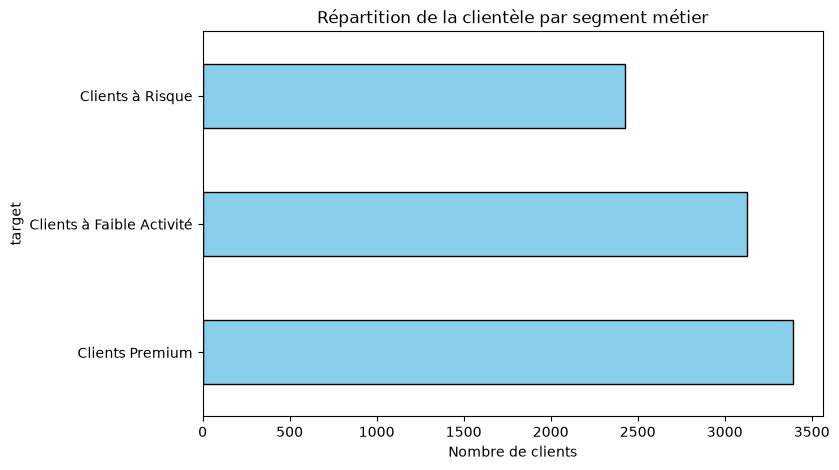

In [63]:
valeurs_nulles = clean_df['target'].isna().sum()
print(f"\n Valeurs manquantes dans la colonne 'target' : {valeurs_nulles}")

proportions_kmeans = clean_df['cluster_final'].value_counts(normalize=True).sort_index()
proportions_target = clean_df['target'].value_counts(normalize=True)

print("\n--- Proportions originales (KMeans) ---")
print((proportions_kmeans * 100).round(2).astype(str) + ' %')

print("\n--- Proportions par Segment Métier (Target) ---")
print((proportions_target * 100).round(2).astype(str) + ' %')

plt.figure(figsize=(8, 5))
clean_df['target'].value_counts().plot(kind='barh', color='skyblue', edgecolor='black')
plt.title("Répartition de la clientèle par segment métier")
plt.xlabel("Nombre de clients")
plt.show()

# Feature Story 5 : Classification supervisée et évaluation des modèles

In [64]:
X = clean_df[numeric_cols].copy()
y = clean_df['target'].copy()

<Experiment: artifact_location='file:c:/Users/Youcode/Desktop/briefs/Sprint One/Brief Three/notebooks/mlruns/1', creation_time=1791474768496, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791474768496, lifecycle_stage='active', name='Classification_experiment', tags={}, trace_location=None, workspace='default'>

In [66]:
X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify=y
)

In [67]:
logistic_pipe = Pipeline(steps=[
    ("scaler" , StandardScaler()),
    ("model" , LogisticRegression(max_iter=1000))
])

dt_pipe = Pipeline(steps=[
    ("scaler" , StandardScaler()),
    ("model" , DecisionTreeClassifier(random_state=42))
])

rf_pipe = Pipeline(steps=[
    ("scaler" , StandardScaler()),
    ("model" , RandomForestClassifier(
        random_state = 42
    ))
])

svc_pipe = Pipeline(steps=[
    ("scaler" , StandardScaler()),
    ("model" , SVC(random_state=42))
])



logistic_pipe.fit(X_train , y_train)

dt_pipe.fit(X_train , y_train)

rf_pipe.fit(X_train , y_train)

svc_pipe.fit(X_train , y_train)

lgr_y_pred = logistic_pipe.predict(X_test)

dt_y_pred = dt_pipe.predict(X_test)

rf_y_pred = rf_pipe.predict(X_test)

svc_y_pred = svc_pipe.predict(X_test)

lgr_accuracy = accuracy_score(y_test , lgr_y_pred)

lgr_precision = precision_score(y_test , lgr_y_pred , average=None)

lgr_recall = recall_score(y_test , lgr_y_pred, average=None)

lgr_f1 = f1_score(y_test , lgr_y_pred , average=None)


dt_accuracy = accuracy_score(y_test , dt_y_pred)

dt_precision = precision_score(y_test , dt_y_pred , average=None)

dt_recall = recall_score(y_test , dt_y_pred, average=None)

dt_f1 = f1_score(y_test , dt_y_pred , average=None)


rf_accuracy = accuracy_score(y_test , rf_y_pred)

rf_precision = precision_score(y_test , rf_y_pred , average=None)

rf_recall = recall_score(y_test , rf_y_pred, average=None)

rf_f1 = f1_score(y_test , rf_y_pred , average=None)


svc_accuracy = accuracy_score(y_test , svc_y_pred)

svc_precision = precision_score(y_test , svc_y_pred , average=None)

svc_recall = recall_score(y_test , svc_y_pred, average=None)

svc_f1 = f1_score(y_test , svc_y_pred , average=None)

In [72]:
models = {
    'Logistic Regression': (
        logistic_pipe,
        {
            'model__solver': ['lbfgs'],
            'model__C': [0.01, 0.1, 1, 10, 100],
            'model__penalty': [None, 'l2']
            }
    ),
    'Decision Tree': (
        dt_pipe,
        {
            'model__criterion': ['gini', 'entropy'],
            'model__max_depth': [3, 5, 10, 15, 20],
            'model__min_samples_split':[2 ,5],
            'model__min_samples_leaf': [1, 2, 4]
            }
    ),
    'Random Forest': (
        rf_pipe,
        {
            'model__n_estimators':[100 , 200 , 300, 500],
            'model__max_depth': [3, 10, 20],
            'model__min_samples_split':[2 ,5],
            'model__max_features': ['sqrt', 'log2', None]
        }
    ),
    'SVM': (
        svc_pipe,
        {
            'model__C': [0.1, 1, 10, 100],
            'model__gamma': ['scale', 'auto', 0.01, 0.1],
            'model__kernel': ['rbf', 'linear']
        }    )
}

best_overall_model = None
best_overall_score = 0
best_model_name = ""

results = []

for name, (pipeline, param_grid) in models.items():

    grid_search = GridSearchCV(
        pipeline,
        param_grid,
        cv=5,
        scoring='f1_weighted',
        error_score='raise',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    y_pred = grid_search.predict(X_test)

    results.append({
        "name":name,
        "best_params":grid_search.best_params_,
        "score":grid_search.best_score_,
        "confusion_matrix":confusion_matrix(y_test, y_pred),
        "classification_report":classification_report(y_test, y_pred),
        })

    if grid_search.best_score_ > best_overall_score:
        best_overall_score = grid_search.best_score_
        best_overall_model = grid_search.best_estimator_
        best_model_name = name

c:\Users\Youcode\Desktop\briefs\Sprint One\Brief Three\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Youcode\Desktop\briefs\Sprint One\Brief Three\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1421: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


In [73]:
res_df = pd.DataFrame(results)
display(res_df)

,name,best_params,score,confusion_matrix,classification_report
0,Logistic Regression,"{'model__C': 0.01, 'model__penalty': None, 'mo...",0.910681,"[[618, 49, 12], [32, 566, 28], [13, 12, 460]]",precision recall...
1,Decision Tree,"{'model__criterion': 'entropy', 'model__max_de...",0.944938,"[[637, 35, 7], [31, 592, 3], [8, 11, 466]]",precision recall...
2,Random Forest,"{'model__max_depth': 20, 'model__max_features'...",0.968290,"[[653, 23, 3], [14, 607, 5], [5, 12, 468]]",precision recall...
3,SVM,"{'model__C': 10, 'model__gamma': 'scale', 'mod...",0.938934,"[[624, 33, 22], [25, 582, 19], [7, 10, 468]]",precision recall...


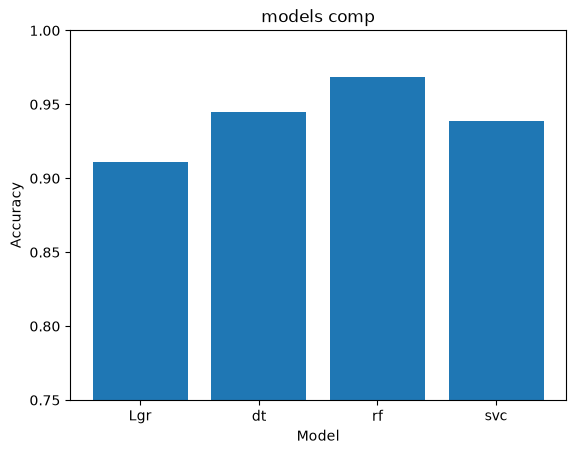

In [74]:
models = [
    "Lgr",
    "dt",
    "rf",
    "svc"
]

accuracies = res_df["score"]


plt.bar(models , accuracies)
plt.title("models comp")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0.75, 1)

plt.show()

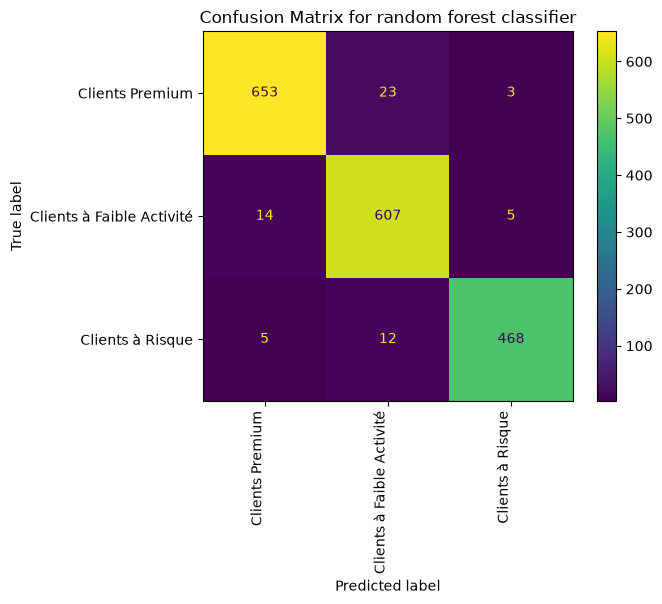

In [75]:
c_matrix = confusion_matrix(y_test , best_overall_model.predict(X_test))
disp = ConfusionMatrixDisplay(
    confusion_matrix = c_matrix,
    display_labels = best_overall_model.classes_,

)

disp.plot()
plt.xticks(rotation=90, ha='right')
plt.title("Confusion Matrix for random forest classifier")
plt.show()

In [76]:
joblib.dump(best_overall_model,"../models/best_overall_model.joblib")


['../models/best_overall_model.joblib']

# Feature Story 6 : Suivi des expérimentations avec MLflow